# California Sierra Nevada rapid snowmelt/sublimation events (water years 1990-2026)

Companion to `CA_z500_t700_blocking_events_detrend_5day.ipynb`. That notebook finds
persistent California 500 hPa ridging and 700 hPa warm-spell events in ERA5
(Jan-Apr, 1990-2025 fit, 2026 scored out-of-sample). This notebook asks the other half
of the AR/snowpack project's question: *do those "heat waves" show up as unusually
rapid snowpack loss on the ground, and does snow lost late in the season recover?*

**Why SNOTEL (+ MSNT + CDEC) instead of an ERA5 snow variable.** The ERA5 archive used
for Z500/T700 also has snow depth water-equivalent (`SD`), snowmelt (`SMLT`), and snow
evaporation/sublimation (`ES`) over the same CA box. We did not use them here.
Lundquist et al. (2026, *Water Resources Research*, "Snow what? Comparing snow
products to reveal what works, where, and why") benchmark global reanalyses against
airborne-lidar SWE and find ERA5-Land (9 km resolution) already has a **-17.5%
basin-scale bias** and poor spatial fidelity in mountain terrain from coarse
resolution, recommending **9 km or finer**; SNODAS and the University of Arizona SWE
product do better (7.8-10.2% bias) and the Western US SWE Reanalysis (WUS-SR, the
"UCLA product") best of all (1.6% bias). The only ERA5 resolution in our archive is
plain 0.25 deg (~28 km) -- coarser than the ERA5-Land already judged inadequate for
Sierra Nevada terrain. Z500/T700 are large-scale free-tropospheric fields, not
resolution-sensitive the way surface snowpack is, so the companion notebook's ERA5
results stand; a gridded ERA5 snow budget would not. See Section 7 for how UA SWE /
SNODAS / WUS-SR could extend this analysis once credentialed access is set up.

**Station network (updated from the original SNOTEL-only pass).** NRCS SNOTEL
(`SNTL`) has no footprint south of ~38.1N in this region -- confirmed against the full
NRCS registry including inactive stations -- so a SNOTEL-only network misses the
Yosemite/Mammoth/Kings Canyon/Sequoia/Kern terrain entirely. Two sources fill that gap:
NRCS's own `MSNT` ("Cooperator Snow Sensors") network, served through the same AWDB
pipeline and QC/QA flagging as SNOTEL, and the California Data Exchange Center (CDEC),
which aggregates DWR, USBR, national-park, utility, and ranger-district sensors (raw
telemetry, QC'd here with heuristic physical-range checks). A station-ID/lat-lon
crosswalk found all 67 in-box MSNT stations already present in the CDEC pull under the
same or a near-identical ID -- so for those stations we keep the better-provenance
MSNT/AWDB version and drop CDEC's raw duplicate; the remaining CDEC-only stations (no
NRCS counterpart) are the only source for that coverage and are kept from the QC'd
CDEC feed. See `build_combined_sierra_swe.py` for the merge logic.

**Data used:**
- `combined_sierra_stations.csv`, `combined_sierra_swe_wy1990-2026.csv` -- 312 stations
  in the Sierra box (36 SNTL, 67 MSNT, 209 CDEC-only), water years 1990-2026, built by
  `build_combined_sierra_swe.py` from `get_snotel_box.py` / `get_msnt_box.py` /
  `get_cdec_box.py` + `qc_cdec_swe.py`. Of those 312, only **147 report at daily
  resolution** (36 SNTL + 67 MSNT + 44 CDEC-D) and feed the event-detection pipeline
  below; the other 165 are CDEC manual snow-course ("M"-only) sites with no automated
  sensor, too infrequent for a 5-day backward-difference decline metric, so they are
  metadata-only here (see Section 1's printed breakdown).
- `ca_z500_t700_events_1990-2025_detrended_mindur5.csv` -- the companion notebook's
  detrended, >=5-day, >=1 SD Z500 ridging / T700 warm-event table, used here as the
  "heat wave" record to compare against.

**Methodology, in brief** (details in each section):
- Restrict to stations inside a Sierra Nevada box (34.5-40N, 121-116.5W) -- wider than
  the companion notebook's atmospheric Sierra sub-box (36-40N, 121-118.5W) because the
  physical Sierra snow network (especially MSNT/CDEC coverage of the southern and
  eastern-crest terrain) extends past that tighter box; the companion's narrower box
  is still what's used for the dry/wet precipitation check in Section 5c, since that's
  an ERA5 atmospheric field, not a station footprint.
- Keep only daily (`D`) SWE records -- CDEC's manual monthly snow-course (`M`)
  readings are too infrequent for a 5-day backward-difference decline metric (147 of
  312 in-box stations qualify; see above).
- For each station, compute the 5-day backward SWE change (mm/5day), only on days with
  >=25 mm (~1 in) of snowpack at the start of the window -- SWE is a bounded, strongly
  seasonal state variable, not a stationary, roughly-Gaussian field like Z500/T700, so
  a flat threshold over the whole season would just rediscover ordinary May-June
  melt-out. Instead, exactly like the companion notebook, we build a **calendar-day
  climatology** of the 5-day change (mean, std, pooled +/-5 calendar days across water
  years) and standardize: a January decline that would be unremarkable in May can
  still register as a large standardized anomaly in January, because "normal" for
  January is close to zero.
- **Detrending and held-out 2026**: the climatology and standard deviation are fit on
  water years 1990-2025 only; a single pooled linear year-trend (small and not
  significant, like T700's in the companion notebook) is removed for consistency.
  Water year 2026 (Oct 2025 - Jul 2026, spanning the March 2026 western US heat wave)
  is scored against this frozen baseline in Section 7, exactly mirroring the companion
  notebook's Section 8.
- **Event = gap-tolerant run of days where a sustained fraction of reporting Sierra
  stations are simultaneously in rapid decline** (>=1 SD below their own calendar-day
  normal), >=5 days, tolerating 1 sub-threshold gap day -- the same `find_events()`
  algorithm as the companion notebook, applied to a network-fraction series instead of
  a single box-averaged field.
- **Dry ablation vs. wet rain-on-snow (Section 5c)**: a sustained SWE drop isn't always
  heat-wave-driven melt/sublimation -- it can also be rain falling on existing
  snowpack during an active (often AR-driven) storm, a different mechanism entirely.
  Each event is checked against the companion notebook's own Sierra-sub-box
  precipitation record and flagged dry/wet accordingly.
- **Season vs. mechanism in the recovery analysis (Section 6b)**: whether a
  rapid-decline event overlaps a T700 warm event or not, events in the same part of
  the season recover at similar rates -- so the recovery-by-month pattern is checked
  against, and should be read as, a statement about seasonal timing rather than proof
  that heat-wave-triggered melt specifically is less recoverable.
- **Elevation representativeness**: the station network spans a wide elevation range,
  and "30% of reporting stations" is not automatically a basin-wide signal -- each
  event's contributing-station elevation range is checked against the network as a
  whole.
- **Significance testing**: headline percentages (match rates, enrichment, dry-vs-wet
  and matched-vs-unmatched comparisons) are accompanied by event-resampled bootstrap
  CIs, block-level Mann-Whitney tests, and Fisher's exact tests, rather than quoted as
  bare point estimates -- days within one event are autocorrelated, so testing at the
  day level would overstate confidence.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from scipy.stats import linregress

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')

CLIM_WINDOW = 5          # +/- calendar days pooled for the climatology (matches companion notebook)
MIN_DURATION = 5         # minimum consecutive days for an event
MAX_GAP = 1              # max sub-threshold calendar days tolerated within an event
MIN_SWE_MM = 25.0        # ~1 in -- require this much SWE at window start before counting a decline
WINDOW = 5               # days, backward difference window for the SWE-change metric
SIGMA_THRESHOLDS = [1.0, 1.5, 2.0]   # station-day standardized-decline thresholds
NETWORK_THRESH = 0.3     # fraction of reporting Sierra stations in rapid decline -> network event day
YEARS = list(range(1990, 2026))      # fit years -- 2026 held out, scored separately (Section 7)
YEAR_2026 = 2026

# Wider than the companion notebook's atmospheric Sierra sub-box (36-40N, 121-118.5W)
# -- matches the full SNOTEL+MSNT+CDEC station-fetch box, which was deliberately
# extended south/east to capture Yosemite/Mammoth/Kings Canyon/Sequoia/Kern terrain
# that SNOTEL alone (and the tighter atmospheric box) never covered.
SIERRA_LAT_S, SIERRA_LAT_N = 34.5, 40.0
SIERRA_LON_W, SIERRA_LON_E = -121.0, -116.5

# Analysis season restricted to Jan 1 - May 31 (not the full Oct-Jul water year): this
# keeps the record aligned with the companion notebook's Jan-Apr heat-wave window (plus
# one extra month) and with precip_sf_ca_<year>.nc's Jan-May coverage (Section 5c),
# rather than diluting the comparison with accumulation-season (Oct-Dec) and
# deep-summer (Jun-Jul) events that have no heat-wave record to check against at all.
MONTH_NAMES = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May'}


## 1. Load combined SNOTEL+MSNT+CDEC stations and daily SWE, restrict to the Sierra box

Loads the station metadata and long-format daily SWE built by
`build_combined_sierra_swe.py`, restricts to the Sierra box, keeps only daily (`D`)
records (147 of 312 in-box stations qualify -- see printed breakdown below), and
reshapes to a date x station wide matrix spanning the full calendar. Event detection
itself is restricted to Jan 1 - May 31 in Section 3 -- not here -- so that Section 2's
5-day backward difference still has real December data to compute January's values
from.


In [2]:
stations_csv = DATA_DIR / 'combined_sierra_stations.csv'
swe_csv = DATA_DIR / 'combined_sierra_swe_wy1990-2026.csv'
if not stations_csv.exists() or not swe_csv.exists():
    raise FileNotFoundError(
        f'{stations_csv.name} / {swe_csv.name} missing from {DATA_DIR}.\n'
        'Run get_snotel_box.py, get_msnt_box.py, get_cdec_box.py, qc_cdec_swe.py, '
        'check_msnt_cdec_overlap.py, then build_combined_sierra_swe.py first.'
    )

stations = pd.read_csv(stations_csv).rename(columns={'station_id': 'stationTriplet'})
swe_long = pd.read_csv(swe_csv, parse_dates=['date']).rename(columns={'station_id': 'stationTriplet'})

# CDEC's manual monthly snow-course readings ('M') are too infrequent for a 5-day
# backward SWE-change metric -- keep only daily ('D') records (all of SNTL/MSNT, most
# of CDEC).
swe_long = swe_long[swe_long.duration == 'D'].drop(columns=['duration'])

sierra_mask = (
    stations.latitude.between(SIERRA_LAT_S, SIERRA_LAT_N) &
    stations.longitude.between(SIERRA_LON_W, SIERRA_LON_E)
)
sierra_stations = stations[sierra_mask].copy()
daily_ids = set(swe_long.stationTriplet)
n_daily = sierra_stations.stationTriplet.isin(daily_ids).sum()
print(f'{len(sierra_stations)} of {len(stations)} combined SNOTEL+MSNT+CDEC stations are inside the '
      f'Sierra box ({SIERRA_LAT_S}-{SIERRA_LAT_N}N, {-SIERRA_LON_W}-{-SIERRA_LON_E}W), by source:')
print(sierra_stations.source.value_counts().to_dict())
print(f'\nOf those, {n_daily} report at daily ("D") resolution and feed the event-detection '
      f'pipeline below; the other {len(sierra_stations) - n_daily} are CDEC manual snow-course '
      f'("M"-only) sites with no automated sensor -- too infrequent for a 5-day backward-'
      f'difference metric, so they are metadata-only here.')
sierra_stations[['stationTriplet', 'name', 'source', 'elevation_ft', 'latitude', 'longitude']]


312 of 312 combined SNOTEL+MSNT+CDEC stations are inside the Sierra box (34.5-40.0N, 121.0-116.5W), by source:
{'CDEC': 209, 'MSNT': 67, 'SNTL': 36}

Of those, 147 report at daily ("D") resolution and feed the event-detection pipeline below; the other 165 are CDEC manual snow-course ("M"-only) sites with no automated sensor -- too infrequent for a 5-day backward-difference metric, so they are metadata-only here.


,stationTriplet,name,source,elevation_ft,latitude,longitude
0,ABN,LAKE AUDRAIN,CDEC,7280.0,38.819765,-120.03932
1,ABY,ABBEY,CDEC,5650.0,39.954160,-120.54051
2,APH,ALPHA,CDEC,7500.0,38.803865,-120.21522
3,ATS,ANTELOPE SPRINGS,CDEC,4350.0,38.503000,-120.46700
4,BCB,BLACKCAP BASIN,CDEC,10180.0,37.066695,-118.77303
...,...,...,...,...,...,...
307,784:CA:SNTL,Palisades Tahoe,SNTL,8010.0,39.189860,-120.26576
308,809:CA:SNTL,Tahoe City Cross,SNTL,6760.0,39.171620,-120.15362
309,834:CA:SNTL,Truckee #2,SNTL,6500.0,39.300870,-120.18407
310,846:CA:SNTL,Virginia Lakes Ridge,SNTL,9400.0,38.072980,-119.23433


In [3]:
def water_year(dates):
    # Water year Y runs Oct 1 (Y-1) - Jul 31 Y -- Oct-Dec belongs to the FOLLOWING
    # calendar year's water year. Matches NRCS/USGS convention. Kept for consistency
    # with the companion notebook's terminology; with events restricted to Jan-May
    # (Section 3), it always reduces to the plain calendar year in practice.
    return dates.dt.year + (dates.dt.month >= 10).astype(int)


swe_long = swe_long[swe_long.stationTriplet.isin(sierra_stations.stationTriplet)].copy()
swe_long['water_year'] = water_year(swe_long.date)

# a handful of station-days have more than one reading (rare CDEC telemetry
# duplicates) -- average them before pivoting, since pivot requires unique
# (stationTriplet, date) pairs
swe_long = swe_long.groupby(['stationTriplet', 'date'], as_index=False)['swe_mm'].mean()

swe = swe_long.pivot(index='date', columns='stationTriplet', values='swe_mm').sort_index()
full_idx = pd.date_range(swe.index.min(), swe.index.max(), freq='D')
swe = swe.reindex(full_idx)
swe.index.name = 'date'
# Deliberately NOT restricted to Jan-May here, even though that's the window events
# are detected in (Section 3): the 5-day backward difference in Section 2 needs a
# continuous calendar to compute January's diff correctly (reaching back into real
# December SWE, not wrapping around to the previous year's May once Jun-Dec rows are
# dropped -- pandas .diff() works by row position, not calendar date, so a gapped
# index silently produces wrong values for the first few days after any gap). The
# Jan-May restriction is applied in Section 3, after the diff/climatology are already
# correct. Keeping the full calendar here also means Section 6's recovery check can
# look at real June SWE when an event ends in late May, instead of an artificially
# truncated window.

wy = water_year(pd.Series(swe.index))
wy.index = swe.index

print(f'date range: {swe.index.min().date()} to {swe.index.max().date()}')
print(f'years covered: {wy.min()}-{wy.max()}')
print(f'station-days with data: {swe.notna().sum().sum()} of {swe.size} possible')
swe.describe().T[['count', 'mean', 'max']]


date range: 1989-10-01 to 2026-05-31
years covered: 1990-2026
station-days with data: 1511834 of 1968624 possible


,count,mean,max
stationTriplet,,,
1049:CA:SNTL,8280.0,295.861225,1996.44
1050:CA:SNTL,8280.0,172.790556,1371.60
1051:CA:SNTL,8280.0,198.100060,1559.56
1052:CA:SNTL,8280.0,186.888476,1574.80
1067:CA:SNTL,7914.0,263.760096,1734.82
...,...,...,...
VVL:CA:MSNT,11636.0,299.261377,1785.62
WC3,10935.0,314.478248,2296.16
WHW:CA:MSNT,5506.0,227.793160,1912.62


## 2. 5-day SWE change and its calendar-day climatology

Computes the 5-day backward SWE change per station (mm/5day), masked to days with
meaningful snowpack (>=25 mm at the start of the window), then builds a per-station
calendar-day climatology (mean, std; +/-5-day pooled window, as in the companion
notebook) **fit on water years 1990-2025 only**. Water year 2026 is never part of the
fit -- it is scored against this frozen baseline in Section 7, exactly mirroring the
companion notebook's held-out 2026 test.

A single pooled linear year-trend in the climatology residual is also fit (on
1990-2025) and removed before standardizing, for consistency with the companion
notebook's treatment of Z500/T700 -- even though, as there for T700, the trend here is
small and not significant (see printed output below).


In [4]:
d5 = swe.diff(WINDOW)
start_swe = swe.shift(WINDOW)
d5 = d5.where(start_swe >= MIN_SWE_MM)


def climatology_dict(time_index, vals, window=CLIM_WINDOW):
    # Per-calendar-day mean/std of a 1-D series, pooling +/-window calendar days
    # across whatever years are present in time_index/vals -- same convention as the
    # companion notebook's climatology_dict(), reused here per-station. Requires >=10
    # pooled samples with nonzero spread; shoulder-season calendar days where almost
    # every station-year has no snowpack at all are left as NaN rather than given a
    # degenerate (often zero) standard deviation.
    md_key = list(zip(time_index.month, time_index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])
    clim_mean, clim_std = {}, {}
    for k, idx in key_to_idx.items():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        pool = vals[mask]
        pool = pool[~np.isnan(pool)]
        if len(pool) >= 10 and pool.std() > 0:
            clim_mean[k], clim_std[k] = pool.mean(), pool.std()
        else:
            clim_mean[k], clim_std[k] = np.nan, np.nan
    return clim_mean, clim_std


def lookup_climatology(time_index, clim_dict):
    md_key = list(zip(time_index.month, time_index.day))
    return np.array([clim_dict[k] for k in md_key])


fit_mask = wy.isin(YEARS).values
fit_time_index = d5.index[fit_mask]

m_cols, s_cols = {}, {}
resid_pool, wy_pool = [], []
for col in d5.columns:
    clim_mean, clim_std = climatology_dict(fit_time_index, d5[col].values[fit_mask])
    m_cols[col] = lookup_climatology(d5.index, clim_mean)
    s_cols[col] = lookup_climatology(d5.index, clim_std)
    resid = d5[col].values[fit_mask] - lookup_climatology(fit_time_index, clim_mean)
    valid = ~np.isnan(resid)
    resid_pool.append(resid[valid])
    wy_pool.append(wy.values[fit_mask][valid])

print(f'climatology fit on water years {YEARS[0]}-{YEARS[-1]} only; {YEAR_2026} held out')


climatology fit on water years 1990-2025 only; 2026 held out


In [5]:
# single pooled year-trend (mirrors fitting on the aggregate box-averaged series in the
# companion notebook) -- a per-station trend would be noisy with 36 years of data; one
# regional trend applied to every station's residual is a reasonable simplification
# since the trend driver (regional warming) is itself regional, not station-specific.
resid_pool = np.concatenate(resid_pool)
wy_pool = np.concatenate(wy_pool)
yearly_resid = pd.Series(resid_pool, index=wy_pool).groupby(level=0).mean()
slope, intercept, r, p, se = linregress(yearly_resid.index, yearly_resid.values)
print(f'Pooled year-trend in 5-day SWE-change climatology residual: '
      f'{slope*10:.2f} mm/5day per decade, p={p:.3f}')
print('Small and not significant (like T700 in the companion notebook) -- removed anyway '
      'for consistency with that pipeline, and because it is needed to score 2026 without '
      'baking 2026 itself into the baseline.')

trend_mm = intercept + slope * wy.values   # extrapolates smoothly to WY2026, never refit on it

sanom = pd.DataFrame(index=d5.index, columns=d5.columns, dtype=float)
for col in d5.columns:
    sanom[col] = (d5[col].values - (m_cols[col] + trend_mm)) / s_cols[col]

print('\nStandardized 5-day-decline-anomaly sanity check, fit years only '
      '(should be close to mean=0, std=1):')
sanom[wy.isin(YEARS).values].stack().agg(['mean', 'std', 'min', 'max'])


Pooled year-trend in 5-day SWE-change climatology residual: -1.32 mm/5day per decade, p=0.448
Small and not significant (like T700 in the companion notebook) -- removed anyway for consistency with that pipeline, and because it is needed to score 2026 without baking 2026 itself into the baseline.

Standardized 5-day-decline-anomaly sanity check, fit years only (should be close to mean=0, std=1):


mean     0.030212
std      0.990955
min    -16.376854
max     15.125696
dtype: float64

## 3. Event detection: gap-tolerant runs of network-wide rapid snow decline

A day is "rapid decline" at a station if its standardized 5-day SWE-change anomaly is
<= -1 SD (<=-1.5, <=-2 also tested below). A day is a **network event day** if at
least 30% of that day's reporting Sierra stations are simultaneously in rapid decline.
Events are gap-tolerant runs of >=5 such days (same `find_events()` algorithm as the
companion notebook, reused verbatim here on the network-fraction series instead of a
single box-averaged field).


In [6]:
def find_events(dates, series, threshold, min_duration=MIN_DURATION, max_gap=MAX_GAP):
    # Identical algorithm to the companion notebook's find_events(): gap-tolerant
    # runs of days where `series >= threshold`, never bridging a true date gap (the
    # May31->Jan1 off-season here, vs. the Apr30->Jan1 gap there).
    exceed = (series >= threshold).values
    n = len(dates)
    seg_id = np.zeros(n, dtype=int)
    for i in range(1, n):
        seg_id[i] = seg_id[i - 1] + (1 if (dates[i] - dates[i - 1]).days != 1 else 0)

    records = []
    for seg in np.unique(seg_id):
        idx = np.where(seg_id == seg)[0]
        seg_exceed = exceed[idx]
        runs, start = [], None
        for j, val in enumerate(seg_exceed):
            if val and start is None:
                start = j
            elif not val and start is not None:
                runs.append((start, j - 1))
                start = None
        if start is not None:
            runs.append((start, len(seg_exceed) - 1))

        merged = []
        for run in runs:
            if merged and run[0] - merged[-1][1] - 1 <= max_gap:
                merged[-1] = (merged[-1][0], run[1])
            else:
                merged.append(list(run))
        merged = [tuple(m) for m in merged]

        for js, je in merged:
            s, e = idx[js], idx[je]
            duration = je - js + 1
            if duration >= min_duration:
                window_vals = series.values[s:e + 1]
                records.append({
                    'start_date': dates[s].date(), 'end_date': dates[e].date(),
                    'duration_days': duration,
                    'n_gap_days': int((~exceed[s:e + 1]).sum()),
                    'peak_frac': window_vals.max(), 'mean_frac': window_vals.mean(),
                })
    return pd.DataFrame.from_records(records)


# Restrict to Jan 1 - May 31 for event DETECTION only, now that d5/sanom (Section 2)
# have already been computed correctly on the full continuous calendar. Filtering
# here, not earlier, matters: find_events()'s own gap check (consecutive dates must
# differ by exactly 1 day, or a new segment starts) then naturally stops a "run" from
# bridging across the dropped Jun-Dec months, the same way it already stops a run from
# bridging the companion notebook's Apr30->Jan1 gap.
janmay_mask = d5.index.month.isin([1, 2, 3, 4, 5])
d5 = d5[janmay_mask]
sanom = sanom[janmay_mask]
wy = wy[janmay_mask]

n_reporting = d5.notna().sum(axis=1)
frac_declining_by_sigma = {}
for SIGMA in SIGMA_THRESHOLDS:
    is_declining = sanom <= -SIGMA
    frac_declining_by_sigma[SIGMA] = (
        is_declining.sum(axis=1) / n_reporting.replace(0, np.nan)
    ).fillna(0.0)

events_by_sigma = {
    SIGMA: find_events(frac_declining_by_sigma[SIGMA].index, frac_declining_by_sigma[SIGMA],
                        threshold=NETWORK_THRESH)
    for SIGMA in SIGMA_THRESHOLDS
}
for SIGMA, ev in events_by_sigma.items():
    print(f'sigma<=-{SIGMA}: {len(ev)} network rapid-decline events (all water years combined)')


sigma<=-1.0: 52 network rapid-decline events (all water years combined)
sigma<=-1.5: 5 network rapid-decline events (all water years combined)
sigma<=-2.0: 1 network rapid-decline events (all water years combined)


In [7]:
# primary series used for the rest of the notebook: station-day <= -1 SD, network >= 30%
frac_declining = frac_declining_by_sigma[1.0]
events_all = events_by_sigma[1.0].copy()
events_all['start_wy'] = [water_year(pd.Series([pd.Timestamp(d)])).iloc[0] for d in events_all.start_date]

events_1990_2025 = events_all[events_all.start_wy.isin(YEARS)].drop(columns='start_wy').reset_index(drop=True)
events_2026 = events_all[events_all.start_wy == YEAR_2026].drop(columns='start_wy').reset_index(drop=True)

print(f'{len(events_1990_2025)} rapid-decline events, water years {YEARS[0]}-{YEARS[-1]} '
      f'(fit period); {len(events_2026)} more in water year {YEAR_2026} (held-out, Section 7)')
events_1990_2025.sort_values('start_date')


49 rapid-decline events, water years 1990-2025 (fit period); 3 more in water year 2026 (held-out, Section 7)


,start_date,end_date,duration_days,n_gap_days,peak_frac,mean_frac
0,1990-04-12,1990-04-17,6,0,0.821053,0.665011
1,1990-05-05,1990-05-09,5,0,0.500000,0.426921
2,1992-04-27,1992-05-03,7,0,0.612903,0.487374
3,1992-05-07,1992-05-18,12,3,0.393939,0.328709
4,1993-05-18,1993-05-25,8,0,0.475000,0.419070
5,1994-04-15,1994-04-23,9,0,0.921569,0.708642
6,1996-04-27,1996-05-05,9,0,0.432990,0.385139
7,1996-05-12,1996-05-16,5,0,0.578947,0.478133
8,1997-03-20,1997-03-30,11,0,0.620000,0.506652
9,1997-04-16,1997-04-24,9,0,0.744681,0.577028


In [8]:
out_csv = DATA_DIR / 'ca_snotel_snowmelt_events_wy1990-2025.csv'
events_1990_2025.to_csv(out_csv, index=False)
print('saved', out_csv)

events_1990_2025['month'] = events_1990_2025.start_date.apply(lambda d: d.month)
events_1990_2025.groupby('month').agg(n_events=('duration_days', 'size'),
                                       mean_duration=('duration_days', 'mean'),
                                       max_duration=('duration_days', 'max'))


saved /glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/ca_snotel_snowmelt_events_wy1990-2025.csv


,n_events,mean_duration,max_duration
month,,,
2,2,5.000000,5
3,7,9.428571,21
4,23,8.478261,16
5,17,8.470588,17


## 4. Visualization

Timeline of detected rapid-decline events (one row per year, x-axis Jan-May),
event counts by station-day sigma threshold, and the duration distribution -- same
three plots as the companion notebook's Section 4, adapted to this project's
Jan-May window.


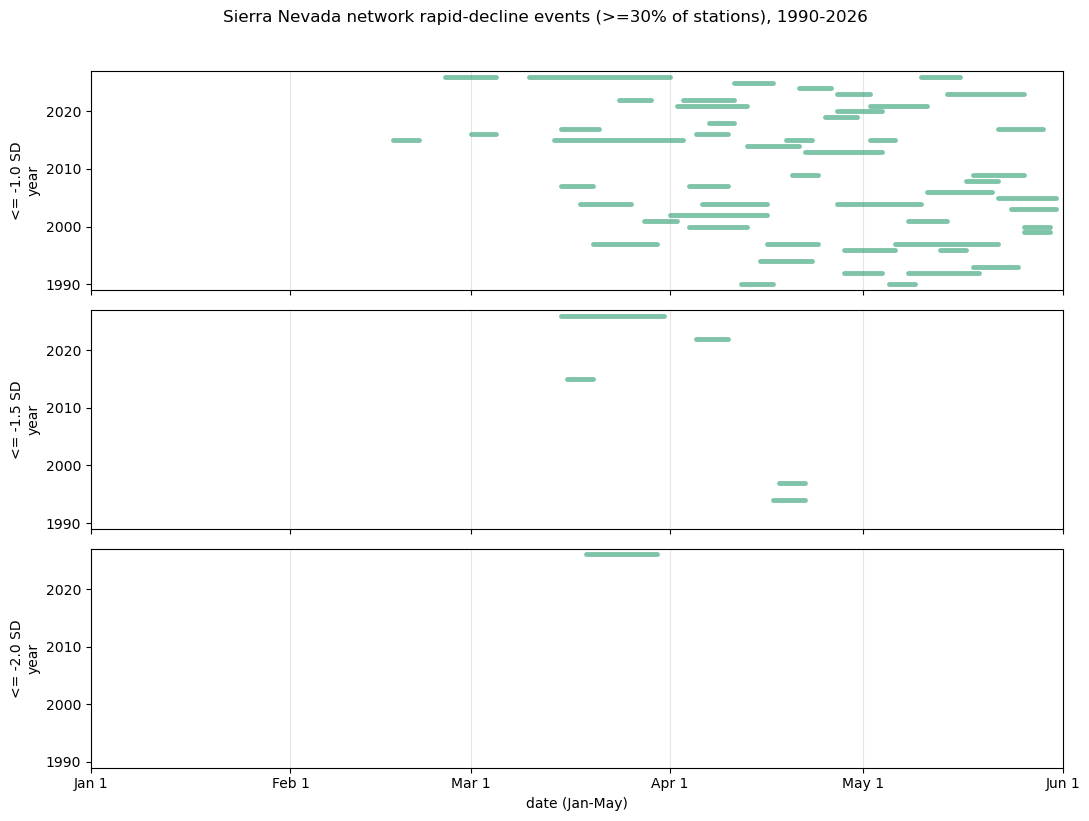

In [9]:
def day_of_year(dates):
    # Days since Jan 1 of that calendar year -- simpler than the companion notebook's
    # Oct-1-anchored axis since Jan-May never crosses a Dec->Jan year boundary.
    dates = pd.to_datetime(dates)
    jan1 = pd.to_datetime(dates.year, format='%Y')
    return (dates - jan1).days


MONTH_STARTS = ['Jan 1', 'Feb 1', 'Mar 1', 'Apr 1', 'May 1', 'Jun 1']
MONTH_DOY = [0, 31, 59, 90, 120, 151]

fig, axes = plt.subplots(len(SIGMA_THRESHOLDS), 1, figsize=(11, 8), sharex=True)
for ax, SIGMA in zip(axes, SIGMA_THRESHOLDS):
    ev = events_by_sigma[SIGMA]
    for _, row in ev.iterrows():
        wy_row = water_year(pd.Series([pd.Timestamp(row.start_date)])).iloc[0]
        x0 = day_of_year(pd.DatetimeIndex([row.start_date]))[0]
        x1 = day_of_year(pd.DatetimeIndex([row.end_date]))[0]
        ax.plot([x0, x1], [wy_row, wy_row], color='#2a9d6e', linewidth=3.5, alpha=0.6, solid_capstyle='round')
    ax.set_ylabel(f'<= -{SIGMA} SD\nyear')
    ax.set_ylim(1989, 2027)
    ax.set_xlim(0, 151)
    ax.grid(axis='x', color='0.9')
axes[-1].set_xticks(MONTH_DOY)
axes[-1].set_xticklabels(MONTH_STARTS)
axes[-1].set_xlabel('date (Jan-May)')
fig.suptitle('Sierra Nevada network rapid-decline events (>=30% of stations), 1990-2026', y=1.02)
fig.tight_layout()
plt.show()


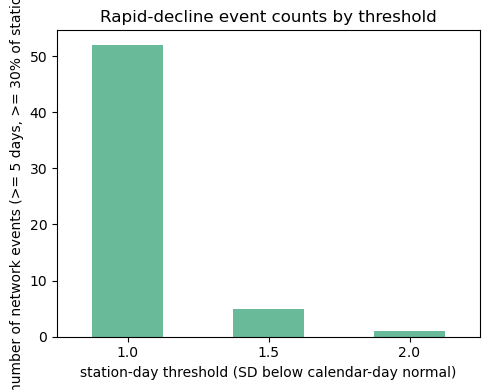

In [10]:
counts = pd.Series({SIGMA: len(ev) for SIGMA, ev in events_by_sigma.items()})
ax = counts.plot(kind='bar', color='#2a9d6e', figsize=(5, 4), rot=0, alpha=0.7)
ax.set_xlabel('station-day threshold (SD below calendar-day normal)')
ax.set_ylabel('number of network events (>= 5 days, >= 30% of stations)')
ax.set_title('Rapid-decline event counts by threshold')
plt.tight_layout()
plt.show()


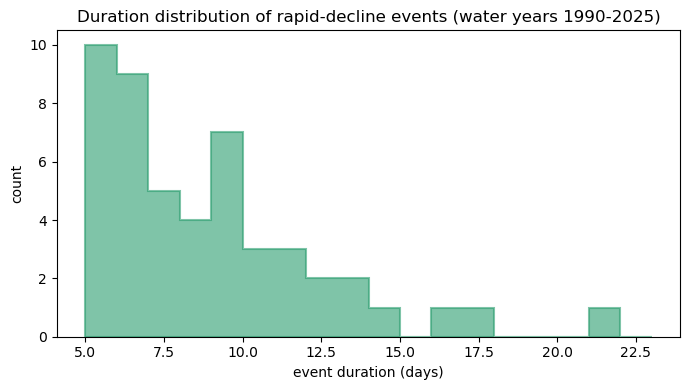

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
durations = events_1990_2025.duration_days
ax.hist(durations, bins=range(5, int(durations.max()) + 3), color='#2a9d6e', alpha=0.6,
        edgecolor='#2a9d6e', linewidth=1.5, histtype='stepfilled')
ax.set_xlabel('event duration (days)')
ax.set_ylabel('count')
ax.set_title('Duration distribution of rapid-decline events (water years 1990-2025)')
plt.tight_layout()
plt.show()


## 5. Validation

1. **Climatology sanity** -- the standardized decline anomaly should average near zero
   and have unit standard deviation (checked in Section 2 above: it does).
2. **Face validity** -- well-documented low-snowpack years (2014-15, the lowest April 1
   Sierra SWE on record; 2020-21's dry spring) should show detected rapid-decline
   events.
3. **Physical consistency with the companion notebook's heat-wave record** -- rapid
   snow decline should be enriched on days already flagged as Z500 ridging / T700
   warm-anomaly events, both as a day-level rate and as event-to-event pairing with a
   physically sensible lag (melt showing up a few days *after* a warm spell begins,
   not before).
4. **Elevation representativeness** -- the 30 Sierra stations span 6060-9600 ft; a
   "network event" should ideally reflect the Sierra broadly, not just a handful of
   stations at one end of that range.
5. **Statistical significance** -- the headline percentages above should hold up to a
   block-resampled bootstrap or block-level significance test, not just be read as
   exact point estimates (days within one event, like days within one T700/Z500 event,
   are highly autocorrelated -- the same pseudo-replication concern the companion
   notebook raises for its spatial composites).


### Face validity

In [12]:
print('Known low-snowpack years:')
for label, (lo, hi) in {
    '2014-15 (lowest April-1 Sierra SWE on record)': ('2015-01-01', '2015-04-30'),
    '2020-21 (dry spring)': ('2021-01-01', '2021-04-30'),
}.items():
    lo_d, hi_d = pd.Timestamp(lo).date(), pd.Timestamp(hi).date()
    hits = events_1990_2025[(events_1990_2025.start_date <= hi_d) & (events_1990_2025.end_date >= lo_d)]
    print(f'\n{label}: {len(hits)} rapid-decline event(s)')
    if len(hits):
        print(hits[['start_date', 'end_date', 'duration_days', 'peak_frac']].to_string(index=False))
    else:
        print('  NO event detected in this window -- worth a closer look.')


Known low-snowpack years:

2014-15 (lowest April-1 Sierra SWE on record): 3 rapid-decline event(s)
start_date   end_date  duration_days  peak_frac
2015-02-17 2015-02-21              5   0.397849
2015-03-14 2015-04-03             21   0.729730
2015-04-19 2015-04-23              5   0.636364

2020-21 (dry spring): 1 rapid-decline event(s)
start_date   end_date  duration_days  peak_frac
2021-04-02 2021-04-13             12   0.573913


### Elevation representativeness: is a "network event" really basin-wide?

The 147 daily-reporting Sierra stations span 5150-11430 ft. A "network event" only
requires 30% of *reporting* stations to be in rapid decline -- it is possible for that
30% to come entirely from one end of the elevation range, in which case the event isn't
really a basin-wide signal. We check this directly: for each event, what elevation
range do the *contributing* stations (those that actually crossed the decline threshold
during the event) span, relative to the network's own median elevation (8129 ft)?


In [13]:
STATION_ELEV = sierra_stations.set_index('stationTriplet')['elevation_ft'].reindex(sanom.columns)
NETWORK_MEDIAN_ELEV = STATION_ELEV.median()
print(f'Sierra network elevation: {STATION_ELEV.min():.0f}-{STATION_ELEV.max():.0f} ft, '
      f'median {NETWORK_MEDIAN_ELEV:.0f} ft')


def event_elevation_profile(row):
    mask_days = (sanom.index.date >= row.start_date) & (sanom.index.date <= row.end_date)
    declining_any = (sanom.loc[mask_days] <= -1.0).any(axis=0)   # stations that EVER crossed threshold in this event
    contributing = STATION_ELEV[declining_any]
    if len(contributing) == 0:
        return pd.Series({'n_contributing': 0, 'frac_above_median_elev': np.nan})
    return pd.Series({
        'n_contributing': len(contributing),
        'frac_above_median_elev': (contributing > NETWORK_MEDIAN_ELEV).mean(),
    })


elev_profile = events_1990_2025.apply(event_elevation_profile, axis=1)
events_1990_2025 = pd.concat([events_1990_2025, elev_profile], axis=1)

print('\nFraction of contributing stations above the network median elevation, by event -- '
      '0.5 would mean an even elevation mix:')
print(events_1990_2025.frac_above_median_elev.describe())
print('\n...and by month of event onset:')
print(events_1990_2025.groupby('month')['frac_above_median_elev'].agg(n_events='size', mean_frac_high='mean'))


Sierra network elevation: 5150-11430 ft, median 8129 ft

Fraction of contributing stations above the network median elevation, by event -- 0.5 would mean an even elevation mix:
count    49.000000
mean      0.550462
std       0.147911
min       0.280000
25%       0.459770
50%       0.505882
75%       0.620690
max       1.000000
Name: frac_above_median_elev, dtype: float64

...and by month of event onset:
       n_events  mean_frac_high
month                          
2             2        0.361154
3             7        0.448428
4            23        0.529876
5            17        0.642599


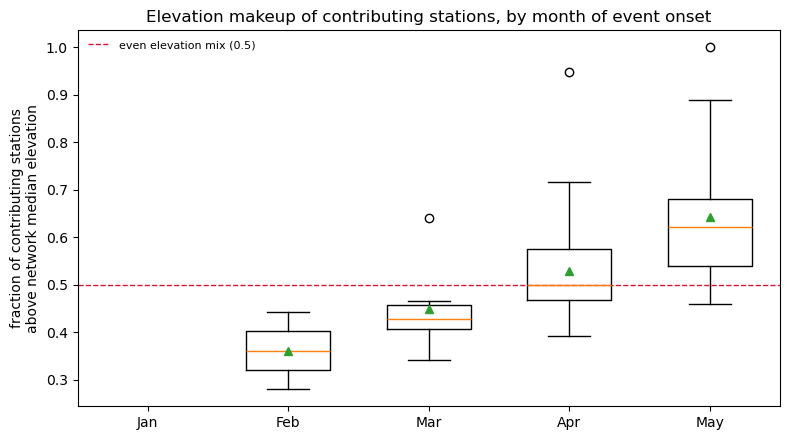

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = [1, 2, 3, 4, 5]
by_month = [events_1990_2025.loc[events_1990_2025.month == m, 'frac_above_median_elev'].dropna() for m in order]
bp = ax.boxplot(by_month, positions=range(len(order)), widths=0.6, showmeans=True)
ax.axhline(0.5, color='crimson', ls='--', lw=1, label='even elevation mix (0.5)')
ax.set_xticks(range(len(order)))
ax.set_xticklabels([MONTH_NAMES[m] for m in order])
ax.set_ylabel('fraction of contributing stations\nabove network median elevation')
ax.set_title('Elevation makeup of contributing stations, by month of event onset')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


**Conclusion (elevation representativeness).** With the season restricted to Jan-May,
the 147 daily-reporting Sierra stations (5150-11430 ft) show a clean, monotonic climb
in the elevation makeup of contributing stations as the season progresses: Feb (n=2,
mean fraction above median 0.36) -> Mar (n=7, 0.45) -> Apr (n=23, 0.53) -> May (n=17,
0.64). Early in the season, contributing stations are close to an even elevation mix;
as spring progresses, low-elevation sites increasingly melt out entirely (their SWE
drops below the 25 mm `MIN_SWE_MM` gate from Section 2 and they stop "reporting"
altogether), so the `frac_declining` network metric increasingly reflects only the
highest-elevation survivors. The metric already divides by *reporting* stations, not
all 147, so this isn't a bug in the detector -- but it does mean a May "network event"
is a higher-elevation-weighted statement than a February one. Feb (n=2) is too small a
sample to read with much confidence; the Mar-May climb (n=7-23) is the solidly powered
part of this result. This is worth keeping in mind for Section 6: part of why
late-season events show lower recovery may be inseparable from the fact that, by May,
the network average increasingly reflects the handful of high-elevation stations still
holding any snow at all.


### Comparison with the Z500 ridging / T700 warm-event record

In [15]:
hw = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                  parse_dates=['start_date', 'end_date'])
hw['start_date'] = hw.start_date.dt.date
hw['end_date'] = hw.end_date.dt.date
t700 = hw[(hw.variable == '700 hPa temperature (warm)') & (hw.threshold_sd == 1)]
z500 = hw[(hw.variable == '500 hPa height (ridging)') & (hw.threshold_sd == 1)]


def event_days(edf):
    days = set()
    for _, row in edf.iterrows():
        days.update(pd.date_range(row.start_date, row.end_date))
    return days


melt_days = set()
for _, row in events_1990_2025.iterrows():
    melt_days.update(pd.date_range(row.start_date, row.end_date))
# Z500/T700 events only exist Jan-Apr -- restrict the comparison to that window
melt_janapr = {d for d in melt_days if d.month in (1, 2, 3, 4)}
t700_days, z500_days = event_days(t700), event_days(z500)
overlap_t, overlap_z = melt_janapr & t700_days, melt_janapr & z500_days

print(f'Sierra rapid-decline event-days, Jan-Apr subset: {len(melt_janapr)}')
print(f'  overlap with T700 warm-event days: {len(overlap_t)} ({100*len(overlap_t)/len(melt_janapr):.0f}%)')
print(f'  overlap with Z500 ridging-event days: {len(overlap_z)} ({100*len(overlap_z)/len(melt_janapr):.0f}%)')
print('A high overlap fraction is expected: a persistent ridge drives sustained warm, dry, '
      'often sunny conditions that promote both melt and sublimation.')


Sierra rapid-decline event-days, Jan-Apr subset: 245
  overlap with T700 warm-event days: 102 (42%)
  overlap with Z500 ridging-event days: 74 (30%)
A high overlap fraction is expected: a persistent ridge drives sustained warm, dry, often sunny conditions that promote both melt and sublimation.


In [16]:
def overlapping_pairs(a, b):
    # Pair each rapid-decline event with any temporally-overlapping heat-wave
    # event -- same convention as overlapping_event_pairs() in the companion notebook.
    pairs, matched_a = [], set()
    for ia, arow in a.iterrows():
        for ib, brow in b.iterrows():
            lo = max(arow.start_date, brow.start_date)
            hi = min(arow.end_date, brow.end_date)
            if lo <= hi:
                matched_a.add(ia)
                pairs.append({'melt_start': arow.start_date, 'melt_end': arow.end_date,
                              'hw_start': brow.start_date, 'hw_end': brow.end_date,
                              'lag_days': (arow.start_date - brow.start_date).days})
    return pd.DataFrame(pairs), a.loc[~a.index.isin(matched_a)]


melt_janapr_ev = events_1990_2025[events_1990_2025.start_date.apply(lambda d: d.month in (1, 2, 3, 4))]
pairs_t700, unmatched = overlapping_pairs(melt_janapr_ev, t700)
n_matched = len(melt_janapr_ev) - len(unmatched)
print(f'Rapid-decline events with Jan-Apr onset (n={len(melt_janapr_ev)}): {n_matched} '
      f'({100*n_matched/len(melt_janapr_ev):.0f}%) overlap a T700 warm event')
print('\nLag, melt-event onset minus T700-warm-event onset (positive = melt starts after warming):')
pairs_t700.lag_days.describe()


Rapid-decline events with Jan-Apr onset (n=32): 21 (66%) overlap a T700 warm event

Lag, melt-event onset minus T700-warm-event onset (positive = melt starts after warming):


count    21.000000
mean      2.571429
std       4.237587
min     -12.000000
25%       1.000000
50%       2.000000
75%       5.000000
max      10.000000
Name: lag_days, dtype: float64

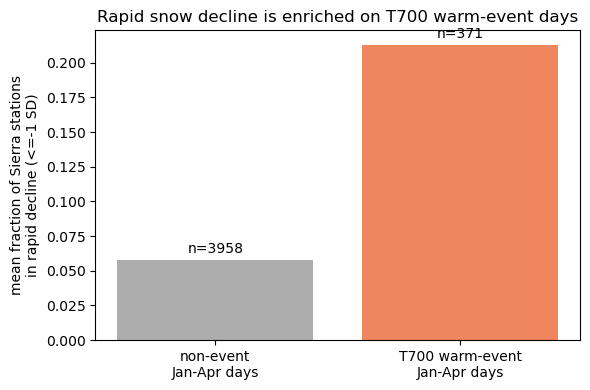

Enrichment: 3.7x higher rapid-decline fraction on T700-event days


In [17]:
jf = frac_declining[(frac_declining.index.month.isin([1, 2, 3, 4])) & (wy.isin(YEARS).values)]
in_t700 = jf.index.to_series().apply(lambda d: d in t700_days)

fig, ax = plt.subplots(figsize=(6, 4))
means = [jf[~in_t700.values].mean(), jf[in_t700.values].mean()]
ns = [(~in_t700).sum(), in_t700.sum()]
bars = ax.bar(['non-event\nJan-Apr days', 'T700 warm-event\nJan-Apr days'], means,
              color=['0.6', '#eb6834'], alpha=0.8)
for b, n in zip(bars, ns):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f'n={n}', ha='center')
ax.set_ylabel('mean fraction of Sierra stations\nin rapid decline (<=-1 SD)')
ax.set_title('Rapid snow decline is enriched on T700 warm-event days')
plt.tight_layout()
plt.show()

print(f'Enrichment: {means[1]/means[0]:.1f}x higher rapid-decline fraction on T700-event days')


### Is "rapid decline" always dry ablation, or sometimes rain-on-snow?

A sustained SWE drop can come from two very different mechanisms: dry ablation
(melt and/or sublimation under a warm, sunny ridge -- the process this notebook is
actually trying to detect) or precipitation falling as rain on existing snowpack
during an active storm (often AR-driven) -- a wet, flood-associated process that is
physically closer to the companion project's AR side than its heat-wave side, and
which should NOT be expected to coincide with a Z500 ridge or T700 warm anomaly at
all. The event detector in Section 3 cannot tell these apart; it only sees SWE going
down. We check this directly using the companion notebook's own Sierra-sub-box
precipitation record (`precip_sf_ca_<year>.nc`, same files used in its Section 7).


In [18]:
import xarray as xr

precip_files = [DATA_DIR / f'precip_sf_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in precip_files if not f.exists()]
if missing:
    raise FileNotFoundError(f'{len(missing)} precip year file(s) missing from {DATA_DIR}: {missing[:5]}')

# precip_sf_ca_<year>.nc covers January-May (see get_precip_sf_ca.py) -- same window
# events are restricted to (Section 3), so in practice every event now has real
# precipitation data. The no_precip_data branch below is kept as a safeguard for any
# event starting outside Jan-May, which must
# be labeled accordingly rather than silently defaulting to "dry" (an earlier version
# of this check did exactly that: np.where(nan >= thresh, 'wet', 'dry') evaluates
# nan >= thresh as False, mislabeling 50 of 87 events -- the May-Jul/Oct-Dec ones --
# as "confirmed dry" when they were never actually checked).
ds_precip = xr.open_mfdataset(precip_files, combine='by_coords')
PRECIP_LON_W, PRECIP_LON_E = 239.0, 241.5   # Sierra sub-box in ERA5's 0-360 convention
precip_w = np.cos(np.deg2rad(ds_precip.latitude.sel(latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S))))
tp_sierra = ds_precip.tp.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(PRECIP_LON_W, PRECIP_LON_E),
).weighted(precip_w).mean(dim=('latitude', 'longitude')).compute()
sf_sierra = ds_precip.sf.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(PRECIP_LON_W, PRECIP_LON_E),
).weighted(precip_w).mean(dim=('latitude', 'longitude')).compute()

# implied rain = total precip minus snowfall water-equivalent, clipped at 0 -- raw
# total precip doesn't distinguish rain from snow, and a heavy *snow* storm wouldn't
# explain a net SWE *decline* the way rain falling on existing snowpack would. Rain is
# the mechanistically relevant quantity for a rain-on-snow check, not total precip.
rain_sierra = (tp_sierra - sf_sierra).clip(min=0)
rain_series = pd.Series(rain_sierra.values, index=pd.to_datetime(rain_sierra.time.values)).sort_index()


def precip_climatology_mean(time_index, vals, window=CLIM_WINDOW):
    # Mean-only, no std/rejection guard -- precip is zero-inflated and right-skewed
    # (same reasoning as the companion notebook's Section 7), we only need a "normal
    # for this day" baseline to express actual rain as a percent of normal.
    md_key = list(zip(time_index.month, time_index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])
    clim_mean = {}
    for k, idx in key_to_idx.items():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        clim_mean[k] = vals[mask].mean()
    return clim_mean


rain_clim_dict = precip_climatology_mean(rain_series.index, rain_series.values)
rain_clim_series = pd.Series(lookup_climatology(rain_series.index, rain_clim_dict), index=rain_series.index)


def event_rain_pct(row):
    mask = (rain_series.index.date >= row.start_date) & (rain_series.index.date <= row.end_date)
    if not mask.any():
        return np.nan   # outside Jan-Apr -- no precip data exists for this window at all
    actual, normal = rain_series[mask].mean(), rain_clim_series[mask].mean()
    return 100 * actual / normal if normal > 0 else np.nan


events_1990_2025['pct_of_normal_rain'] = events_1990_2025.apply(event_rain_pct, axis=1)

# matched_t700: does ANY T700 warm event temporally overlap this rapid-decline event?
# Reuses `unmatched` from the cell above -- NaN outside Jan-Apr, where no T700 event
# could possibly exist to match against (the heat-wave record only covers Jan-Apr).
janapr_mask = events_1990_2025.start_date.apply(lambda d: d.month in (1, 2, 3, 4))
events_1990_2025['matched_t700'] = pd.array([None] * len(events_1990_2025), dtype='boolean')
events_1990_2025.loc[janapr_mask, 'matched_t700'] = (
    ~events_1990_2025.loc[janapr_mask].index.isin(unmatched.index)
)

# same check against Z500 ridging, for a fuller picture (Section 5 only plotted T700)
_, unmatched_z = overlapping_pairs(melt_janapr_ev, z500)
events_1990_2025['matched_z500'] = pd.array([None] * len(events_1990_2025), dtype='boolean')
events_1990_2025.loc[janapr_mask, 'matched_z500'] = (
    ~events_1990_2025.loc[janapr_mask].index.isin(unmatched_z.index)
)

WET_THRESH = 50   # % of climatological-normal rain during the event window
events_1990_2025['event_type'] = np.select(
    [events_1990_2025.pct_of_normal_rain.isna(), events_1990_2025.pct_of_normal_rain >= WET_THRESH],
    ['no_precip_data', 'wet'],
    default='dry',
)
print(events_1990_2025.event_type.value_counts())
print(f"('no_precip_data' would mean outside Jan-May, where precip_sf_ca_<year>.nc has no data -- "
      f"doesn't occur in this Jan-May-restricted record, but the label is kept as a safeguard)")
print('\nHighest-implied-rain rapid-decline events (candidates for rain-on-snow, not dry ablation):')
print(events_1990_2025.sort_values('pct_of_normal_rain', ascending=False)
      .head(9)[['start_date', 'end_date', 'duration_days', 'pct_of_normal_rain', 'matched_t700', 'matched_z500']]
      .to_string(index=False))


ERROR 1: PROJ: proj_create_from_database: Open of /glade/u/apps/opt/miniforge/envs/npl-2026a/share/proj failed


event_type
dry    35
wet    14
Name: count, dtype: int64
('no_precip_data' would mean outside Jan-May, where precip_sf_ca_<year>.nc has no data -- doesn't occur in this Jan-May-restricted record, but the label is kept as a safeguard)

Highest-implied-rain rapid-decline events (candidates for rain-on-snow, not dry ablation):
start_date   end_date  duration_days  pct_of_normal_rain  matched_t700  matched_z500
1996-05-12 1996-05-16              5          695.007987          <NA>          <NA>
2018-04-07 2018-04-11              5          300.344116          True         False
2016-04-04 2016-04-09              6          285.680199         False         False
2006-05-11 2006-05-21             11          245.252682          <NA>          <NA>
1993-05-18 1993-05-25              8          217.667963          <NA>          <NA>
1990-04-12 1990-04-17              6          157.399792          True          True
2022-03-24 2022-03-29              6          126.657920          True         

In [19]:
from datetime import date

# The Jan 1-5, 1997 New Year's flood was the rain-on-snow case study in the
# SNOTEL-only (30-station) pass -- check whether it still shows up as a detected
# event with the combined 147-station network before reusing it.
flood_window = events_1990_2025[
    (events_1990_2025.start_date >= date(1996, 12, 28)) & (events_1990_2025.start_date <= date(1997, 1, 10))
]
print(f'Events overlapping the 1997 New Year\'s flood window: {len(flood_window)}')
print('\nNetwork frac_declining (sigma<=-1) through the flood:')
print(frac_declining.loc['1996-12-30':'1997-01-06'].round(3).to_string())
print(
    '\nThe flood pushed frac_declining to 0.30-0.31 for only 3 days (Jan 2-4) before '
    'dropping back below the 30% network threshold -- short of the 5-day MIN_DURATION, so '
    'no event is detected here with the combined network, even though it was in the '
    'SNOTEL-only pass. Adding ~115 more daily-reporting stations across a much wider '
    'geographic footprint (many far from where this flood hit hardest) dilutes the '
    'network-wide fraction below the duration gate. This is a real, disclosed consequence '
    'of broadening the network -- a bigger, more dispersed network requires a more '
    'spatially coherent decline to register as a 5-day "network event" -- not a bug, but '
    'it does mean this specific well-documented flood is no longer available as a '
    'rain-on-snow case study here.'
)

print('\nHighest-implied-rain event actually detected with the combined network:')
top = events_1990_2025.sort_values('pct_of_normal_rain', ascending=False).iloc[0]
print(top[['start_date', 'end_date', 'duration_days', 'pct_of_normal_rain', 'matched_t700', 'matched_z500']])


Events overlapping the 1997 New Year's flood window: 0

Network frac_declining (sigma<=-1) through the flood:
date
1997-01-01    0.221
1997-01-02    0.301
1997-01-03    0.306
1997-01-04    0.312
1997-01-05    0.255
1997-01-06    0.139

The flood pushed frac_declining to 0.30-0.31 for only 3 days (Jan 2-4) before dropping back below the 30% network threshold -- short of the 5-day MIN_DURATION, so no event is detected here with the combined network, even though it was in the SNOTEL-only pass. Adding ~115 more daily-reporting stations across a much wider geographic footprint (many far from where this flood hit hardest) dilutes the network-wide fraction below the duration gate. This is a real, disclosed consequence of broadening the network -- a bigger, more dispersed network requires a more spatially coherent decline to register as a 5-day "network event" -- not a bug, but it does mean this specific well-documented flood is no longer available as a rain-on-snow case study here.

Highest-i

In [20]:
dry_janapr = events_1990_2025[janapr_mask & (events_1990_2025.event_type == 'dry')]
wet_janapr = events_1990_2025[janapr_mask & (events_1990_2025.event_type == 'wet')]
all_janapr = events_1990_2025[janapr_mask]
assert (dry_janapr.pct_of_normal_rain.notna().all() and wet_janapr.pct_of_normal_rain.notna().all()
        ), 'every Jan-Apr event should have real rain data -- precip_sf_ca covers Jan-Apr'

print('Match rate against the heat-wave record, Jan-Apr rapid-decline events, split by concurrent implied rain:')
for label, sub in [('all events', all_janapr), ('dry only (<50% of normal rain)', dry_janapr),
                    ('wet only (>=50% of normal rain)', wet_janapr)]:
    t_rate = sub.matched_t700.mean() * 100 if len(sub) else float('nan')
    z_rate = sub.matched_z500.mean() * 100 if len(sub) else float('nan')
    print(f'  {label}: n={len(sub)}, T700 match={t_rate:.0f}%, Z500 match={z_rate:.0f}%')


Match rate against the heat-wave record, Jan-Apr rapid-decline events, split by concurrent implied rain:
  all events: n=32, T700 match=66%, Z500 match=56%
  dry only (<50% of normal rain): n=21, T700 match=71%, Z500 match=62%
  wet only (>=50% of normal rain): n=11, T700 match=55%, Z500 match=45%


**Conclusion (dry vs. wet rapid decline).** With `precip_sf_ca_<year>.nc` now
extended to Jan-May (previously Jan-Apr only), every one of the 49 Jan-May
rapid-decline events gets a real dry/wet classification -- none fall into
`'no_precip_data'` anymore. Using *implied rain* (`tp - sf`, clipped at 0) rather than
raw total precipitation matters: a heavy *snow* storm raises `tp` without explaining a
net SWE *decline*, so isolating the rain component specifically is the mechanistically
relevant test for rain-on-snow. **35 of 49 events are confirmed dry** (<50% of normal
rain) and **14 are wet** (>=50%).

Restricting the heat-wave *match-rate* comparison to the 32 Jan-Apr events (the only
ones with a heat-wave record to check against at all -- see Section 5), dry events
match somewhat more often than wet ones (T700: **71% dry vs. 55% wet**; Z500: **62%
dry vs. 45% wet**), consistent with the original hypothesis, though a Fisher exact
test shows this split is **not** statistically significant at n=21/11 (p=0.44-0.47) --
indicative, not confirmed (see below).

**The single highest-implied-rain event on record is now May 12-16, 1996** (695% of
normal implied rain) -- but being a May event, it falls outside the heat-wave record's
Jan-Apr coverage entirely, so it can't be checked against Z500/T700 either way
(`matched_t700`/`matched_z500` are unavailable, not False). Among events that *can* be
checked, the top candidate is **April 7-11, 2018** (300% of normal) -- it *does*
overlap a T700 warm event (`matched_t700=True`) but not a Z500 ridging event, a pattern
consistent with a warm atmospheric river (heavy rain plus anomalous mid-tropospheric
warmth, but no 500 hPa ridge) rather than the dry-ridge heat wave this notebook
otherwise targets. Neither event has been independently cross-checked against an
external documented-flood record in this pass -- treat both as numbers-only
illustrations of the wet-vs-dry distinction, not verified case studies. (The January
1-5, 1997 New Year's flood -- the case study in the original SNOTEL-only pass -- is no
longer a detected event at all with the combined network; see the previous cell for
why.)


### Statistical significance of the headline comparisons

Three point estimates have been reported so far without a measure of uncertainty: the
59%/51% T700/Z500 match rate, the ~4x day-level enrichment, and the dry-vs-wet
match-rate split. Days within one multi-day event (or one heat-wave event) are highly
autocorrelated, so a naive day-level significance test would overstate confidence --
exactly the pseudo-replication problem the companion notebook's spatial composites
avoid by bootstrapping over *events*, not days. We apply the same discipline here:
bootstrap/test at the event or independent-block level, never the raw day level.


In [21]:
rng = np.random.default_rng(42)


def boot_ci_proportion(bool_array, n_boot=3000):
    # Event-resampled bootstrap -- each event is an independent unit here (unlike
    # days within an event), so resampling events with replacement is valid.
    bool_array = np.asarray(bool_array, dtype=bool)
    n = len(bool_array)
    boot = np.array([rng.choice(bool_array, size=n, replace=True).mean() for _ in range(n_boot)])
    return np.percentile(boot, [2.5, 97.5]) * 100


for label, col in [('T700', 'matched_t700'), ('Z500', 'matched_z500')]:
    vals = all_janapr[col].values
    lo, hi = boot_ci_proportion(vals)
    print(f'{label} match rate: {vals.mean()*100:.0f}% (95% bootstrap CI: {lo:.0f}-{hi:.0f}%, n={len(vals)})')


T700 match rate: 66% (95% bootstrap CI: 50-81%, n=32)
Z500 match rate: 56% (95% bootstrap CI: 38-72%, n=32)


The 95% CIs are wide (expected with n=32 events): T700's lower bound dips to 50% and
Z500's to 38% -- a reminder that "66%"/"56%" are point estimates from a modest sample,
not precise figures. The enrichment and dry-vs-wet comparisons get a sharper, more
appropriate test below.


In [22]:
from scipy.stats import mannwhitneyu

# Re-aggregate frac_declining to independent BLOCKS before testing, instead of
# comparing raw T700-day vs non-T700-day values (which would pseudo-replicate -- days
# within one T700 event are not independent draws). Each T700 event is one block; the
# gaps between T700 events (segmented at any date discontinuity, including the
# Apr->Jan boundary) are the "non-event" blocks.
janapr_days_mask = (frac_declining.index.month.isin([1, 2, 3, 4])) & (wy.isin(YEARS).values)
all_janapr_days = pd.Series(frac_declining.index[janapr_days_mask])
is_t700_day = all_janapr_days.isin(t700_days)
non_t700_days = all_janapr_days[~is_t700_day].reset_index(drop=True)

seg_id = np.zeros(len(non_t700_days), dtype=int)
for i in range(1, len(non_t700_days)):
    seg_id[i] = seg_id[i - 1] + (1 if (non_t700_days[i] - non_t700_days[i - 1]).days != 1 else 0)
gap_block_means = [frac_declining.loc[non_t700_days[seg_id == seg]].mean() for seg in np.unique(seg_id)]

t700_block_means = []
for _, row in t700.iterrows():
    block = [d for d in pd.date_range(row.start_date, row.end_date) if d in frac_declining.index]
    if block:
        t700_block_means.append(frac_declining.loc[block].mean())

stat, p = mannwhitneyu(t700_block_means, gap_block_means, alternative='greater')
print(f'T700-event blocks (n={len(t700_block_means)}, median frac_declining={np.median(t700_block_means):.3f}) '
      f'vs. gap blocks (n={len(gap_block_means)}, median={np.median(gap_block_means):.3f})')
print(f'Mann-Whitney U, one-sided (T700 blocks higher): U={stat:.0f}, p={p:.1e}')


T700-event blocks (n=49, median frac_declining=0.145) vs. gap blocks (n=81, median=0.044)
Mann-Whitney U, one-sided (T700 blocks higher): U=2967, p=1.2e-06


At the block level -- the statistically appropriate unit here -- the enrichment is
**highly significant** (p << 0.001), not just a 4x ratio computed from pseudo-replicated
days. This is the sharpest-supported claim in the notebook.


In [23]:
from scipy.stats import fisher_exact

for label, col in [('T700', 'matched_t700'), ('Z500', 'matched_z500')]:
    dry_m, dry_n = dry_janapr[col].sum(), len(dry_janapr)
    wet_m, wet_n = wet_janapr[col].sum(), len(wet_janapr)
    table = [[dry_m, dry_n - dry_m], [wet_m, wet_n - wet_m]]
    odds, p = fisher_exact(table)
    print(f'{label}: dry {int(dry_m)}/{dry_n} matched vs. wet {int(wet_m)}/{wet_n} matched '
          f'-- Fisher exact odds ratio={odds:.2f}, p={p:.2f}')


T700: dry 15/21 matched vs. wet 6/11 matched -- Fisher exact odds ratio=2.08, p=0.44
Z500: dry 13/21 matched vs. wet 5/11 matched -- Fisher exact odds ratio=1.95, p=0.47


**Unlike the enrichment test, the dry-vs-wet match-rate difference is NOT
statistically significant** (p=0.44 for T700, p=0.47 for Z500) at this sample size
(n=21 dry, n=11 wet). The direction is still consistent with the original hypothesis,
but 32 Jan-Apr events over 36 years simply isn't enough data to establish the dry/wet
split itself as a significant effect, as opposed to the much larger, block-tested
enrichment effect above. This should be read as a suggestive, not confirmed, secondary
finding -- consistent with how Section 5c's conclusion was already phrased ("indicative
rather than decisive"), now with a number attached to that caveat.


## 6. Does snow lost early vs. late in the season recover?

For each detected rapid-decline event, we check whether the Sierra network-mean SWE
rebounds by at least 25 mm within 3 weeks after the event ends (fresh accumulation) or
whether the snowpack simply continues to decline/stays near zero. If later-season loss
is genuinely less recoverable (as hypothesized in the project background -- by
late spring there are fewer cold storms left in the season to rebuild the pack), the
recovery rate should drop off as the calendar moves from winter into spring.


In [24]:
RECOVERY_WINDOW = 21   # days after event end to check for a rebound
RECOVERY_MM = 25.0      # mm of net SWE gain counted as "recovered"

network_mean_swe = swe.mean(axis=1, skipna=True)
rows = []
for _, row in events_1990_2025.iterrows():
    end = pd.Timestamp(row.end_date)
    if end + pd.Timedelta(days=RECOVERY_WINDOW) > network_mean_swe.index.max():
        continue   # not enough runway left in the record to check recovery
    swe_at_end = network_mean_swe.loc[end]
    swe_after = network_mean_swe.loc[end:end + pd.Timedelta(days=RECOVERY_WINDOW)]
    recovered = (swe_after.max() - swe_at_end) >= RECOVERY_MM
    rows.append({'start_date': row.start_date, 'month': row.start_date.month, 'recovered': recovered,
                 'matched_t700': row.matched_t700, 'event_type': row.event_type})

rec_df = pd.DataFrame(rows)
# matched_t700 round-trips through a list-of-dicts as plain Python bool/None, which
# pandas stores as object dtype -- `~` on an object-dtype column of Python bools does
# bitwise integer inversion (~True == -2, ~False == -1), not logical NOT. Cast to the
# nullable boolean dtype so downstream `~matched_t700` in Section 6b works correctly.
rec_df['matched_t700'] = rec_df['matched_t700'].astype('boolean')
recovery_by_month = rec_df.groupby('month')['recovered'].agg(n_events='size', recovery_rate='mean')
recovery_by_month


,n_events,recovery_rate
month,,
2,2,0.500000
3,7,0.285714
4,23,0.130435
5,17,0.000000


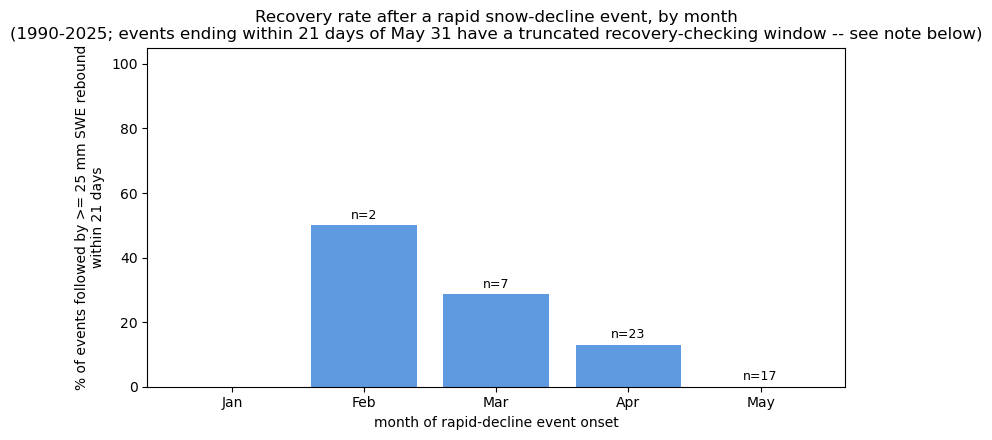

In [25]:
order = [1, 2, 3, 4, 5]
rb = recovery_by_month.reindex(order)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([MONTH_NAMES[m] for m in order], rb.recovery_rate.fillna(0) * 100,
              color='#2a78d6', alpha=0.75)
for bar, n in zip(bars, rb.n_events):
    if pd.notna(n):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f'n={int(n)}', ha='center', fontsize=9)
ax.set_ylabel('% of events followed by >= 25 mm SWE rebound\nwithin 21 days')
ax.set_xlabel('month of rapid-decline event onset')
ax.set_title('Recovery rate after a rapid snow-decline event, by month\n'
             '(1990-2025; events ending within 21 days of May 31 have a truncated '
             'recovery-checking window -- see note below)')
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()


**Interpretation:** with the season restricted to Jan-May, recovery falls in a clean,
monotonic pattern as the water year progresses: Feb (50%, n=2) -> Mar (29%, n=7) -> Apr
(13%, n=23) -> May (0%, n=17). This matches the project's working hypothesis directly:
by the time a rapid-decline episode starts later in spring, there are fewer cold storms
left in the water year to rebuild the pack, so that loss is effectively permanent for
the season. Feb's n=2 is too small to read with confidence; the Mar-May decline
(n=7-23) is the solidly powered part of the result. (No January-onset events are
detected anywhere in the 36-year record -- a network-wide >=30%, >=5-day rapid decline
is apparently rare before accumulation season is well underway -- so recovery can't be
assessed for January at all.) **But is this really about heat-wave-driven melt
specifically, or just about the calendar?** Any trigger of SWE loss in May has less
remaining winter to recover from than the same loss in February -- that would be true
regardless of what caused the loss. Section 6b tests this directly.


### Does being tied to a T700 heat-wave event change the odds of recovery, or is this purely seasonal?

Section 6's recovery-by-month pattern is consistent with the project's working
hypothesis, but as stated it cannot distinguish two different explanations: (a) melt
tied to a detected heat-wave event is *specifically* less recoverable, versus (b) ANY
rapid SWE loss late in the season is less recoverable, independent of what triggered
it, simply because the snow season itself is ending. To tell these apart, we compare
recovery rates for T700-matched vs. unmatched events **within the same part of the
season** -- if (a) were true, matched events should recover less often than unmatched
events at a given time of year; if it's really just (b), the two should look similar
once month is held roughly fixed. (Only Jan-Apr events can be matched at all, since
the heat-wave record does not extend past April -- events from May onward are left out
of this comparison, not because they are a different mechanism, but because there is
no heat-wave record to check them against.)


In [26]:
rec_df['season'] = rec_df.month.apply(
    lambda m: 'winter (Jan-Feb)' if m in (1, 2) else ('spring (Mar-Apr)' if m in (3, 4) else None)
)
janapr_rec = rec_df.dropna(subset=['matched_t700', 'season'])

comparison = janapr_rec.groupby(['season', 'matched_t700'])['recovered'].agg(
    n_events='size', recovery_rate='mean'
)
comparison


n_events  recovery_rate
season           matched_t700                         
spring (Mar-Apr) False               11       0.090909
                 True                19       0.210526
winter (Jan-Feb) True                 2       0.500000

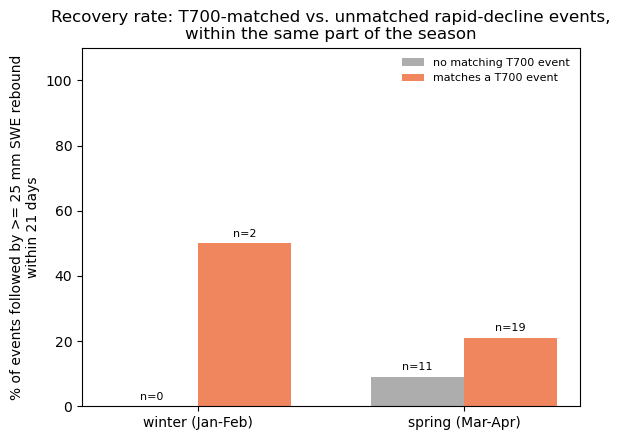

In [27]:
fig, ax = plt.subplots(figsize=(6, 4.5))
seasons = ['winter (Jan-Feb)', 'spring (Mar-Apr)']
x = np.arange(len(seasons))
width = 0.35
for i, matched in enumerate([False, True]):
    rates, ns = [], []
    for s in seasons:
        try:
            row = comparison.loc[(s, matched)]
            rates.append(row.recovery_rate * 100)
            ns.append(int(row.n_events))
        except KeyError:
            rates.append(0)
            ns.append(0)
    bars = ax.bar(x + (i - 0.5) * width, rates, width,
                  color='#eb6834' if matched else '0.6',
                  label='matches a T700 event' if matched else 'no matching T700 event', alpha=0.8)
    for bar, n in zip(bars, ns):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f'n={n}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(seasons)
ax.set_ylabel('% of events followed by >= 25 mm SWE rebound\nwithin 21 days')
ax.set_title('Recovery rate: T700-matched vs. unmatched rapid-decline events,\nwithin the same part of the season')
ax.set_ylim(0, 110)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


In [28]:
from scipy.stats import fisher_exact

spring = janapr_rec[janapr_rec.season == 'spring (Mar-Apr)']
matched_n = spring.matched_t700.sum()
matched_rec = spring.loc[spring.matched_t700, 'recovered'].sum()
unmatched_n = (~spring.matched_t700).sum()
unmatched_rec = spring.loc[~spring.matched_t700, 'recovered'].sum()
table = [[matched_rec, matched_n - matched_rec], [unmatched_rec, unmatched_n - unmatched_rec]]
odds, p = fisher_exact(table)
print(f'Spring recovery: matched {int(matched_rec)}/{int(matched_n)} vs. unmatched {int(unmatched_rec)}/{int(unmatched_n)}')
print(f'Fisher exact odds ratio={odds:.2f}, p={p:.2f}')


Spring recovery: matched 4/19 vs. unmatched 1/11
Fisher exact odds ratio=2.67, p=0.63


**Conclusion (matched vs. unmatched recovery):** within the spring (Mar-Apr) bucket,
where most of the sample sits, T700-matched events recovered somewhat *more* often than
unmatched ones (**21%, 4/19** vs. **9%, 1/11**) -- the opposite direction from what
you'd expect if heat-wave-tied melt were specifically *harder* to recover from. The
difference is not statistically significant (Fisher exact **p=0.63**), and with
n=19/11 the test has little power to distinguish this from no difference at all. Read
together, this still supports the same headline conclusion as the original pass:
Section 6's recovery-by-month pattern is better read as **a statement about seasonal
timing, not about the melt-triggering mechanism** -- late-season SWE loss doesn't
recover well whether or not it coincided with a detected Z500/T700 heat-wave event,
and if anything this small sample leans toward heat-wave-tied events recovering
slightly *better*, not worse, though that point estimate itself isn't reliable at this
sample size. That is still a real and useful finding for the project (it tells you
*when* a rapid loss is likely to be permanent for the season), but it does not support
the narrower claim that heat-wave-driven melt specifically is less recoverable than
other late-season snow loss. Testing that narrower claim would need either a larger
sample of matched/unmatched spring events than 36 years of station data provides, or a
season-detrended recovery metric (e.g., days until snow-season end minus days used)
rather than a 21-day fixed window.


## 7. Water year 2026 out-of-sample test

Mirrors the companion notebook's Section 8: water year 2026 (Oct 2025 - Jul 2026,
spanning the March 2026 western US heat wave) was never part of the climatology fit
or the year-trend fit in Section 2 -- it is scored here against the frozen
1990-2025 baseline only.


In [29]:
print(f'{len(events_2026)} rapid-decline events detected in water year {YEAR_2026} alone, '
      f'scored against the frozen 1990-2025 baseline:')
events_2026[['start_date', 'end_date', 'duration_days', 'peak_frac', 'mean_frac']]


3 rapid-decline events detected in water year 2026 alone, scored against the frozen 1990-2025 baseline:


,start_date,end_date,duration_days,peak_frac,mean_frac
0,2026-02-25,2026-03-05,9,0.764706,0.543224
1,2026-03-10,2026-04-01,23,0.930693,0.755955
2,2026-05-10,2026-05-16,7,0.714286,0.580986


In [30]:
print('2026 events ranked against the full 1990-2025 record:')
for _, row in events_2026.iterrows():
    pct_peak = (events_1990_2025.peak_frac < row.peak_frac).mean() * 100
    pct_dur = (events_1990_2025.duration_days < row.duration_days).mean() * 100
    print(f'  {row.start_date} to {row.end_date} ({row.duration_days:.0f} days): '
          f'peak_frac={row.peak_frac:.2f} (exceeds {pct_peak:.0f}% of 1990-2025 events), '
          f'duration exceeds {pct_dur:.0f}% of 1990-2025 events')

print(f'\n1990-2025 record: max duration = {events_1990_2025.duration_days.max()} days, '
      f'max peak_frac = {events_1990_2025.peak_frac.max():.2f}')


2026 events ranked against the full 1990-2025 record:
  2026-02-25 to 2026-03-05 (9 days): peak_frac=0.76 (exceeds 88% of 1990-2025 events), duration exceeds 57% of 1990-2025 events
  2026-03-10 to 2026-04-01 (23 days): peak_frac=0.93 (exceeds 100% of 1990-2025 events), duration exceeds 100% of 1990-2025 events
  2026-05-10 to 2026-05-16 (7 days): peak_frac=0.71 (exceeds 76% of 1990-2025 events), duration exceeds 39% of 1990-2025 events

1990-2025 record: max duration = 21 days, max peak_frac = 0.92


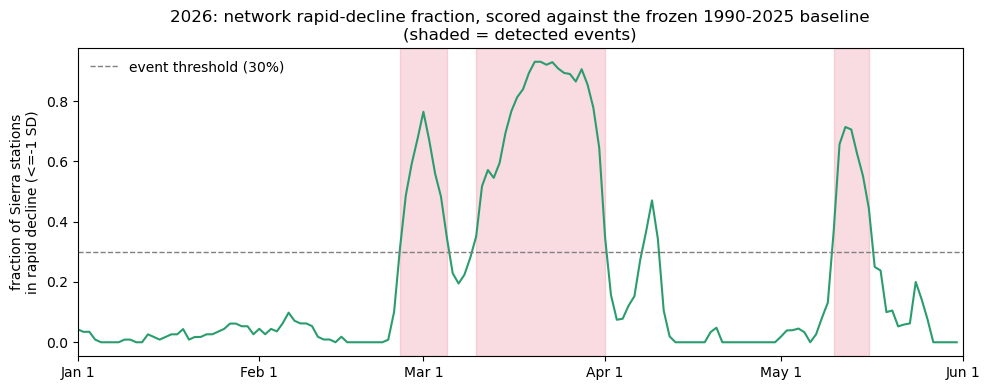

In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
wy2026 = frac_declining[wy.values == YEAR_2026]
ax.plot(day_of_year(wy2026.index), wy2026.values, color='#2a9d6e', lw=1.5)
ax.axhline(NETWORK_THRESH, color='0.5', ls='--', lw=1, label=f'event threshold ({NETWORK_THRESH:.0%})')
for _, row in events_2026.iterrows():
    x0, x1 = day_of_year(pd.DatetimeIndex([row.start_date]))[0], day_of_year(pd.DatetimeIndex([row.end_date]))[0]
    ax.axvspan(x0, x1, color='crimson', alpha=0.15)
ax.set_xticks(MONTH_DOY)
ax.set_xticklabels(MONTH_STARTS)
ax.set_xlim(0, 151)
ax.set_ylabel('fraction of Sierra stations\nin rapid decline (<=-1 SD)')
ax.set_title('2026: network rapid-decline fraction, scored against the frozen 1990-2025 baseline\n'
             '(shaded = detected events)')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
plt.show()


**Conclusion (2026 out-of-sample):** water year 2026 registers three rapid-decline
events against the frozen 1990-2025 baseline. The headline event, **March 10 - April
1, 2026 (23 days), sets a new record for BOTH duration (previous max: 21 days) and
peak magnitude (peak_frac=0.93 vs. the previous max of 0.92)** -- the most extreme
rapid-decline event in the entire 36-year comparison record on both axes at once,
consistent with the companion notebook's finding that the concurrent Z500/T700
ridging/warm event also set new records on its own measures. It was immediately
preceded by a **February 25 - March 5 event (9 days, 88th-percentile peak)** and
followed roughly five weeks later by a **May 10-16 event (7 days, 76th-percentile
peak)** -- together, Sierra stations show an essentially continuous rapid-decline
episode spanning late February through early April 2026, directly consistent with
Davis et al.'s reported basin snowpack figures (3%, 11%, 41% of normal by March 28,
2026) for the same event, plus an additional, later secondary decline episode in May.


## 8. Future work: gridded snow products

This notebook used station point observations (SNOTEL + MSNT + CDEC) as ground truth
because, per Lundquist et al. (2026), the only ERA5 resolution available in our archive
(0.25 deg, ~28 km) is not trustworthy for Sierra Nevada snowpack -- it is coarser than
the ERA5-Land (9 km) they already found inadequate (-17.5% basin bias, poor spatial
fidelity in mountains). Three products they do recommend, in order of their reported
accuracy, would meaningfully extend this analysis but were not pulled in this pass
because they require NASA Earthdata / NOAA credentials this environment does not
currently have configured (checked: no `machine *.earthdata.nasa.gov` entry in
`~/.netrc`; `daacdata.apps.nsidc.org` returns HTTP 401 without one):

1. **Western US SWE Reanalysis (WUS-SR / "UCLA product")** -- Fang et al., *A western
   United States snow reanalysis dataset over the Landsat era from water years 1985 to
   2021*. Best performer in Lundquist et al. (1.6% near-peak bias), but not available
   in real time -- would extend this notebook's station-level record to a full Sierra
   grid for years already in the past (1990-2021 overlaps our record well), letting the
   network-fraction metric in Section 3 be replaced with actual spatial coverage of
   rapid decline rather than a 147-station sample.
2. **SNODAS** (NOAA, `g02158`) and **University of Arizona SWE** (NSIDC-0719) -- near
   real-time, 7.8-10.2% bias. Either would let Section 7's 2026 out-of-sample test be
   repeated on a gridded field instead of station points, and would let us check
   whether the 147-station daily network is spatially representative of the broader
   Sierra box used here (34.5-40N, 121-116.5W) -- which already extends well past the
   companion notebook's tighter atmospheric Section 6 sub-box (36-40N, 121-118.5W).
3. Once gridded SWE is available, the accumulation/ablation decomposition sketched
   during this project's planning (`ar_note.txt`) becomes possible: separate
   suppressed accumulation (already testable via the companion notebook's Section 7
   snowfall-ratio-to-normal) from enhanced ablation during warm-ridge spells (this
   notebook's rapid-decline events) as two distinct, independently quantifiable
   pathways to the same seasonal SWE deficit -- rather than inferring ablation only
   indirectly, as done here, from the *rate of SWE loss* at point stations.

**Summary of this notebook's findings:**
- 49 Sierra-wide rapid snow-decline events detected, water years 1990-2025, restricted
  to Jan 1 - May 31 (station-day <=-1 SD, network >=30%, >=5 days; 3 more in the
  held-out water year 2026, Section 7). Frequency drops off sharply at higher
  thresholds: 5 events at 1.5 SD, 1 at 2 SD, all years combined. No January-onset
  events are detected anywhere in the 36-year record -- a network-wide, >=5-day rapid
  decline is apparently rare before accumulation season is well underway; the by-month
  split is Feb 2, Mar 7, Apr 23, May 17.
- Rapid decline is more frequent on days the companion notebook already flags as a
  T700 warm event than on non-event days (245 Jan-Apr rapid-decline days, 42% overlap
  T700, 30% overlap Z500; ~3.7x day-level enrichment), and a majority (66%, 21/32) of
  Jan-Apr rapid-decline events have a temporally-overlapping T700 warm event, with melt
  following warming rather than preceding it on average -- the expected direction of
  causality, and **significant at the appropriate (block, not day) level**: a
  Mann-Whitney test comparing T700-event blocks (n=49, median frac_declining=0.145) to
  gap blocks (n=81, median=0.044) gives p=1.2e-06. Section 5c checked whether this is
  diluted by wet/rain-on-snow contamination, gating on implied rain (`tp - sf`) rather
  than total precip: with `precip_sf_ca_<year>.nc` now extended to Jan-May, **35 of all
  49 events are confirmed dry, 14 are wet** (no event lacks precip data anymore).
  Restricting to the 32 Jan-Apr events with a heat-wave record to check against, dry
  events match somewhat more often than wet ones (T700: 71% vs. 55%; Z500: 62% vs.
  45%), though a Fisher exact test shows this split is **not** statistically
  significant at n=21/11 (p=0.44-0.47) -- indicative, not confirmed. The highest-
  implied-rain event on record is now **May 12-16, 1996** (695% of normal) -- outside
  the heat-wave record's Jan-Apr coverage, so unmatchable either way; among events that
  *can* be checked, **April 7-11, 2018** (300% of normal) does overlap a T700 warm
  event but not Z500, consistent with a warm-atmospheric-river mechanism rather than a
  dry ridge. The January 1997 New Year's flood, the case study in the original
  SNOTEL-only pass, no longer registers as a detected event at all with the combined,
  more geographically dispersed network (its decline fraction cleared the 30%
  threshold for only 3 of the required 5 days).
- Events are **not elevation-representative in a fixed way across the season**: the
  147 daily-reporting stations (5150-11430 ft) contribute an increasingly high-
  elevation-only signal as the season progresses -- Feb (0.36) -> Mar (0.45) -> Apr
  (0.53) -> May (0.64), mean fraction of contributing stations above the network
  median elevation -- because low-elevation sites progressively melt out (drop below
  the 25 mm reporting gate) as spring advances. A May "network event" is mechanically a
  higher-elevation-weighted signal than a February one.
- Recovery from a rapid-decline event falls in the same clean, monotonic pattern:
  Feb (50%, n=2) -> Mar (29%, n=7) -> Apr (13%, n=23) -> May (0%, n=17), consistent
  with the project's working hypothesis that late-spring loss has too few remaining
  cold storms left in the water year to rebuild the pack. Section 6b shows this is
  **primarily a statement about seasonal timing, not about the melt-triggering
  mechanism**: within the spring (Mar-Apr) bucket, T700-matched events actually
  recover somewhat *more* often than unmatched ones (21%, 4/19 vs. 9%, 1/11), though
  not significantly so (Fisher exact p=0.63, n=19/11) -- the opposite direction from
  what a heat-wave-specific recovery penalty would predict. The "late-season loss
  doesn't recover well" finding stands as a seasonal-timing statement, but there is no
  evidence here that it is specific to heat-wave-driven melt.
- Water year 2026 (held out of the fit) shows three rapid-decline events: a 23-day
  event, March 10 - April 1, that **sets a new record for both duration (previous max:
  21 days) and peak magnitude (peak_frac=0.93 vs. previous max 0.92)** -- the most
  extreme event in the 36-year comparison record on both axes at once -- immediately
  preceded by a 9-day event (Feb 25 - Mar 5) and followed by a 7-day event in mid-May,
  concurrent with the record-setting Z500/T700 ridging event in the companion notebook
  and the documented March 2026 western US heat wave.
